# Spatial summary selection

How a building's depth is read off the depth grid: the max, mean, median or 90th percentile of the cells its footprint touches, or the cell holding its centroid. Each panel shows building depth from the surveyed July 2021 depths against the post-event placard damage class, with the Pearson correlation (r) between the two. The mean gives the strongest association and is the summary used throughout.

The data come from `July2021Validation.placard_building_depths()`, the same buildings and depths `main.py calibrate` scores.

In [1]:
import os, sys, logging

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, REPO_ROOT)
logging.disable(logging.INFO)

# Drop any project modules a long-running kernel already imported, so this cell
# always runs the code as it is on disk now (Python never reloads a changed file
# on its own -- that is what raised "cannot import name 'pearson'").
for name in [n for n in sys.modules if n == "modules" or n.startswith("modules.")]:
    del sys.modules[name]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modules.exposure_module.exposure_module import SPATIAL_SUMMARIES
from modules.validation_module.july_2021_validation import July2021Validation
from modules.validation_module.metrics import pearson

FIG_DIR = os.path.join(REPO_ROOT, "out")
CHOSEN = "mean"                        # named in bold; colour is the same for every summary
LABELS = {"max": "Max", "mean": "Mean", "median": "Median", "p90": "90th percentile", "centroid": "Centroid cell"}
DAMAGE_LABELS = {0: "None", 1: "Slight", 2: "Moderate", 3: "Severe"}

# Same print-first style as the paper figures in westport/notebooks/results_analysis.ipynb.
# FIG_WIDTH_IN is the one size knob: type, line weights and markers all scale with it.
# 7.2 in is a journal's full double-column width; the default is that layout enlarged
# for reading on screen, and reduces to the print version by setting FIG_WIDTH_IN = 7.2.
FIG_WIDTH_IN = 13.0
_SCALE = FIG_WIDTH_IN / 7.2
BASE_FONT_PT = 8 * _SCALE
FILL, EDGE = "#C6DBEF", "#08519C"     # light fill under a darker outline: holds in greyscale print

plt.rcParams.update({
    # Serif, as in the other paper figures. Liberation Serif has Times New Roman's
    # metrics, so the layout is the same wherever Times is installed instead.
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    # Bold panel letters go through mathtext; point it at the same serif face so
    # they do not fall back to DejaVu Sans.
    "mathtext.fontset": "custom",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "mathtext.cal": "serif",
    "mathtext.sf": "serif",
    "font.size": BASE_FONT_PT,
    "axes.titlesize": BASE_FONT_PT + 1,
    "axes.labelsize": BASE_FONT_PT + 1,
    "xtick.labelsize": BASE_FONT_PT - 1,
    "ytick.labelsize": BASE_FONT_PT - 1,
    "legend.fontsize": BASE_FONT_PT - 1,
    # Labels, ticks and frame in black, set explicitly so a kernel that ran an
    # earlier style does not leave them grey.
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "xtick.labelcolor": "black",
    "ytick.labelcolor": "black",
    "axes.linewidth": 0.6 * _SCALE,
    "xtick.major.width": 0.6 * _SCALE,
    "ytick.major.width": 0.6 * _SCALE,
    "xtick.major.size": 2.5 * _SCALE,
    "ytick.major.size": 2.5 * _SCALE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
})


def style_axes(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, color="0.85", lw=0.4 * _SCALE, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")


def panel_title(ax, letter, name, chosen=False, pad=14):
    """Bold panel letter and name, the way the paper's other figures label panels."""
    name = f"$\\bf{{{name}}}$" if chosen else name
    ax.set_title(f"$\\bf{{({letter})}}$ {name}", fontsize=BASE_FONT_PT + 1,
                 pad=pad * _SCALE, loc="left")

In [23]:
# Per-building depths under every summary, and each summary's Pearson correlation
# with the damage class.
calibration = July2021Validation()
calibration.scenario_id = 0
buildings = calibration.placard_building_depths()

damage = buildings["DamageNb"].astype(int).to_numpy()
classes = sorted(np.unique(damage))
r = pd.Series({s: pearson(buildings[s], damage) for s in SPATIAL_SUMMARIES}, name="pearson")

counts = pd.Series(damage).value_counts().sort_index()
print(f"{len(buildings):,} buildings; per damage class:", counts.to_dict())
r.round(3)

2,247 buildings; per damage class: {0: 1598, 1: 179, 2: 356, 3: 114}


max         0.657
mean        0.686
median      0.684
p90         0.672
centroid    0.662
Name: pearson, dtype: float64

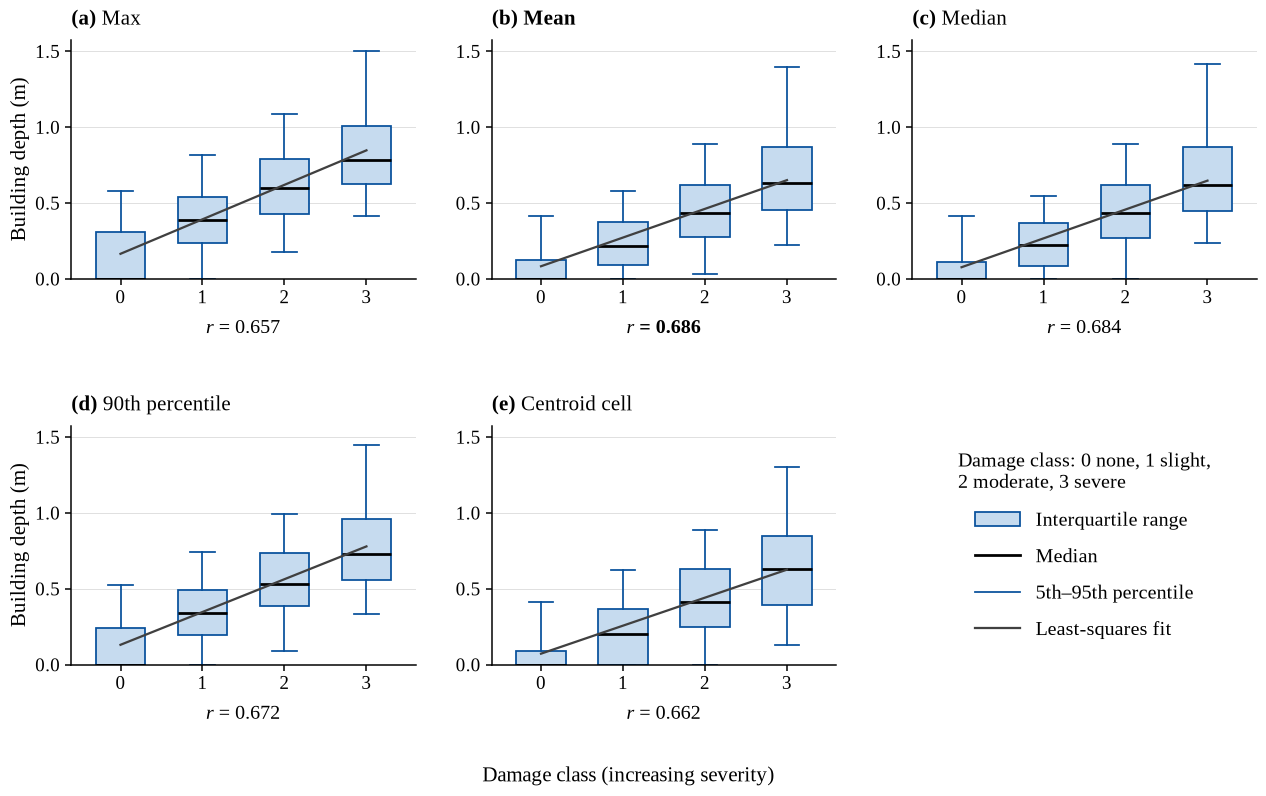

In [5]:
# Figure 1: building depth by damage class, one panel per spatial summary, in two
# rows of three so each panel stays readable at full page width; the sixth slot
# holds the key. Whiskers run to the 5th and 95th percentiles and individual
# buildings beyond them are not drawn: with 1,598 undamaged buildings the outliers
# form solid columns that hide the boxes.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

WHISKERS = (5, 95)
FIT_COLOUR = "0.25"

fig, grid = plt.subplots(2, 3, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.62), sharey=True)
axes = grid.ravel()
for i, (ax, s) in enumerate(zip(axes, SPATIAL_SUMMARIES)):
    bp = ax.boxplot(
        [buildings[s][damage == c] for c in classes], positions=classes, widths=0.6,
        whis=WHISKERS, patch_artist=True, showfliers=False,
        medianprops=dict(color="black", lw=1.1 * _SCALE),
        whiskerprops=dict(color=EDGE, lw=0.7 * _SCALE),
        capprops=dict(color=EDGE, lw=0.7 * _SCALE),
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(FILL)
        patch.set_edgecolor(EDGE)
        patch.set_linewidth(0.7 * _SCALE)

    # Least-squares line of building depth on damage class, fitted to every
    # building: the straight line the panel's Pearson r measures the fit of.
    slope, intercept = np.polyfit(damage, buildings[s], 1)
    ax.plot([classes[0], classes[-1]], [intercept + slope * classes[0], intercept + slope * classes[-1]],
            color=FIT_COLOUR, lw=0.9 * _SCALE, zorder=4)

    panel_title(ax, chr(97 + i), LABELS[s], chosen=(s == CHOSEN), pad=6)
    ax.set_xticks(classes)
    ax.set_xlim(-0.6, classes[-1] + 0.6)
    ax.tick_params(labelleft=True)
    style_axes(ax)
    # The panel's Pearson correlation with damage class, under its tick labels.
    ax.text(0.5, -0.17, f"$r$ = {r[s]:.3f}", transform=ax.transAxes,
            ha="center", va="top", fontsize=BASE_FONT_PT,
            fontweight="bold" if s == CHOSEN else "normal")

for ax in grid[:, 0]:
    ax.set_ylabel("Building depth (m)")
grid[0, 0].set_ylim(bottom=0)

# The free sixth slot carries the key, so the caption need not describe the marks.
key = axes[len(SPATIAL_SUMMARIES)]
key.axis("off")
key.legend(
    handles=[
        Patch(facecolor=FILL, edgecolor=EDGE, linewidth=0.7 * _SCALE, label="Interquartile range"),
        Line2D([], [], color="black", lw=1.1 * _SCALE, label="Median"),
        Line2D([], [], color=EDGE, lw=0.7 * _SCALE, label="5th–95th percentile"),
        Line2D([], [], color=FIT_COLOUR, lw=0.9 * _SCALE, label="Least-squares fit"),
    ],
    loc="center", frameon=False, fontsize=BASE_FONT_PT, handlelength=2.2, labelspacing=0.9,
    title="Damage class: 0 none, 1 slight,\n2 moderate, 3 severe", title_fontsize=BASE_FONT_PT,
)
fig.supxlabel("Damage class (increasing severity)", fontsize=BASE_FONT_PT + 1)
fig.tight_layout(h_pad=2.5, w_pad=1.5)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_spatial_summary_depth_by_damage.{ext}"), dpi=600)
plt.show()

In [2]:
# Figure 2: hourly MAE (all and wet buildings), wet bias, hit rate and CSI by flood driver.
#
# One box per driver, pooling every hour of every event in that driver group
# (from per_timestep_metrics.csv). The grouping is the one in
# westport/notebooks/results_analysis.ipynb (EVENT_GROUPS), so both papers split
# the test events the same way. Box style as there: light blue box, darker
# outline, black median line, whiskers at 1.5 x IQR, hourly outliers hollow.
from modules.lib import VALIDATION_RESULTS_DIR

# Results folder of each model (main.py validate --model ...); MODEL picks the one
# the figures and table below are made for. The 1D-CNN benchmark's files get a
# _cnn1d suffix so they never overwrite the surrogate's.
RUN_CONFIGS = {"flow_matching": "mean_M10_K1_hours12_decode5_seed41",
               "cnn1d": "mean_cnn1d_hours12"}
MODEL = "flow_matching"
RUN_CONFIG = RUN_CONFIGS[MODEL]
FILE_SUFFIX = "" if MODEL == "flow_matching" else f"_{MODEL}"
# Warm-up: hours dropped from the start of every event, here and in Figures 3-4.
# The simulation starts from a dry initial state while the surrogate has no such
# state and already floods houses at the first step (4,265 in event 17), so the
# opening hours score the cold start, not the forecast. SKIP_WARM_UP = False
# keeps every step.
SKIP_WARM_UP = True
WARM_UP_HOURS = 4
SKIP_FIRST_STEPS = WARM_UP_HOURS if SKIP_WARM_UP else 0
EVENT_GROUPS = {
    "River-dominated":   [3, 43, 64, 83],
    "Compound":          [13, 37, 54, 91, 93],
    "Coastal-dominated": [17, 57, 106],
}
SHOW_OUTLIERS = True
SHORT_NAMES = {"River-dominated": "River", "Compound": "Compound", "Coastal-dominated": "Coastal"}

per_timestep = pd.read_csv(os.path.join(VALIDATION_RESULTS_DIR, RUN_CONFIG, "per_timestep_metrics.csv"))
# An event run twice under the same configuration appends its hours twice;
# keep the latest run of each hour.
per_timestep = per_timestep.drop_duplicates(["scenario_id", "time_step"], keep="last")
per_timestep = per_timestep[per_timestep["time_step"] >= SKIP_FIRST_STEPS]
regime_of = {event: regime for regime, events in EVENT_GROUPS.items() for event in events}
per_timestep["regime"] = per_timestep["scenario_id"].map(regime_of)
missing = sorted(set(per_timestep.loc[per_timestep["regime"].isna(), "scenario_id"]))
if missing:
    print("scenarios in no driver group, left out:", missing)

# MAE and bias (forecast - observed) of the ensemble-median depth over all
# buildings and over the observed-wet ones (the buildings crps / crps_wet average
# over; bias only over the wet ones), and the hourly hit rate and CSI. Top row:
# MAE, MAE_wet, hit rate; bottom row: Bias_wet under MAE_wet, CSI under hit
# rate. Subscript t: each box value is one hour's score.
# (grid position, column, y label, which way is better)
panels = [((0, 0), "mae", "MAE$_{t}$ (m)", "lower is better"),
          ((0, 1), "mae_wet", "MAE$_{\\mathrm{wet},\\,t}$ (m)", "lower is better"),
          ((0, 2), "hit_rate", "Hit rate$_{t}$", "higher is better"),
          ((1, 1), "bias_wet", "Bias$_{\\mathrm{wet},\\,t}$ (m)", "0 is unbiased"),
          ((1, 2), "csi", "CSI$_{t}$", "higher is better")]
regimes = list(EVENT_GROUPS)

fig, grid = plt.subplots(2, 3, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66))
grid[1, 0].set_axis_off()
for i, (cell, column, label, better) in enumerate(panels):
    ax = grid[cell]
    data = [per_timestep.loc[per_timestep["regime"] == r, column].dropna().to_numpy() for r in regimes]
    positions = [p for p, d in enumerate(data) if len(d)]
    bp = ax.boxplot(
        [d for d in data if len(d)], positions=positions, widths=0.55, patch_artist=True,
        showfliers=SHOW_OUTLIERS,
        medianprops=dict(color="black", lw=1.1 * _SCALE),
        whiskerprops=dict(color=EDGE, lw=0.7 * _SCALE),
        capprops=dict(color=EDGE, lw=0.7 * _SCALE),
        flierprops=dict(marker="o", markersize=1.6 * _SCALE, markerfacecolor="none",
                        markeredgecolor=EDGE, markeredgewidth=0.4 * _SCALE, alpha=0.55),
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(FILL)
        patch.set_edgecolor(EDGE)
        patch.set_linewidth(0.7 * _SCALE)

    ax.set_xticks(range(len(regimes)))
    ax.set_xticklabels([f"{SHORT_NAMES[r]}\n(n = {len(d)})" for r, d in zip(regimes, data)],
                       fontsize=BASE_FONT_PT - 1.5)
    # Driver label once per column, on its lowest panel.
    if cell[0] == 1 or cell == (0, 0):
        ax.set_xlabel("Flood driver")
    ax.set_xlim(-0.6, len(regimes) - 0.4)
    ax.set_ylabel(f"{label}\n({better})")
    if column in ("hit_rate", "csi"):
        ax.set_ylim(top=1.02)
    if column.startswith("bias"):
        ax.axhline(0, color="0.35", lw=0.6 * _SCALE, zorder=0)
    panel_title(ax, chr(97 + i), "", pad=6)
    style_axes(ax)

fig.tight_layout(h_pad=2.5, w_pad=2)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_mae_bias_hit_rate_csi_by_driver{FILE_SUFFIX}.{ext}"), dpi=600)
plt.show()


In [3]:
# Per-house scores over each whole event, without its first SKIP_FIRST_STEPS hours.
#
# Rebuilt from building_hourly_depth.csv (every house's depth every hour: the
# hydrodynamic simulation's observed_depth and the surrogate's ensemble-median
# depth_median) with the same functions and rules as
# DepthValidation.score_event, which wrote building_event_metrics.csv from all
# the hours. With SKIP_FIRST_STEPS = 0 this reproduces that file. Peak = highest
# hour of each series; onset = first exposed hour (depth > 0.05 m); a house is
# exposed over the event if its peak is; timing only where both sides expose it.
from modules.exposure_module.exposure_module import is_exposed
from modules.validation_module.metrics import hours_between, onset_times, peaks

def building_event_scores(run_config, events=None, forecast_columns="depth_median"):
    """Per-house scores of one run configuration's results folder, one row per
    house per event (optionally only ``events``), without each event's first
    SKIP_FIRST_STEPS hours. ``forecast_columns``: the forecast depth scored, the
    ensemble median by default; a list of columns (e.g. the member percentiles
    depth_min, depth_p25, depth_p75, depth_max) scores each one as a single
    forecast from one read of the file and returns {column: scores}."""
    columns = [forecast_columns] if isinstance(forecast_columns, str) else list(forecast_columns)
    hourly_depth = pd.read_csv(
        os.path.join(VALIDATION_RESULTS_DIR, run_config, "building_hourly_depth.csv"),
        usecols=["scenario_id", "valid_time", "building_id", "observed_depth", *columns])
    if events is not None:
        hourly_depth = hourly_depth[hourly_depth["scenario_id"].isin(events)]
    # Repeated runs of an event append its hours again; keep the latest.
    hourly_depth = hourly_depth.drop_duplicates(["scenario_id", "valid_time", "building_id"], keep="last")

    event_tables = {column: [] for column in columns}
    for scenario_id, event in hourly_depth.groupby("scenario_id"):
        # (times, buildings) per side; hours in order, the first ones dropped.
        observed = event.pivot(index="valid_time", columns="building_id", values="observed_depth").sort_index()
        observed = observed.iloc[SKIP_FIRST_STEPS:]
        times = pd.to_datetime(observed.index)
        observed_peak, observed_peak_time = peaks(observed.to_numpy(), times)
        observed_onset = onset_times(observed.to_numpy(), times)
        observed_exposed = is_exposed(observed_peak)
        for column in columns:
            forecast = event.pivot(index="valid_time", columns="building_id", values=column).sort_index()
            forecast = forecast.iloc[SKIP_FIRST_STEPS:]
            forecast_peak, forecast_peak_time = peaks(forecast.to_numpy(), times)
            forecast_exposed = is_exposed(forecast_peak)
            both = observed_exposed & forecast_exposed
            event_tables[column].append(pd.DataFrame({
                "scenario_id": scenario_id,
                "building_id": observed.columns,
                "observed_peak_depth": observed_peak,
                "forecast_peak_depth": forecast_peak,
                "peak_depth_error": forecast_peak - observed_peak,
                "peak_time_error_h": np.where(both, hours_between(forecast_peak_time, observed_peak_time), np.nan),
                "onset_error_h": np.where(both, hours_between(onset_times(forecast.to_numpy(), times),
                                                              observed_onset), np.nan),
                "exposure_outcome": np.select([both, observed_exposed, forecast_exposed],
                                              ["hit", "miss", "false_alarm"], default="correct_negative"),
            }))
    scores = {column: pd.concat(tables, ignore_index=True) for column, tables in event_tables.items()}
    return scores[forecast_columns] if isinstance(forecast_columns, str) else scores


building_events = building_event_scores(RUN_CONFIG)
building_events["regime"] = building_events["scenario_id"].map(regime_of)
print(f"first {SKIP_FIRST_STEPS} hour(s) of each event dropped;",
      building_events["exposure_outcome"].value_counts().to_dict())

first 4 hour(s) of each event dropped; {'correct_negative': 35306, 'hit': 26599, 'false_alarm': 4153, 'miss': 614}


In [4]:
# Detection of inundated buildings that are in the computational domain (5556) for an individual event.
# Timing error based on the first time that was inundated in the reference model vs our model vs 1dcnn model

# Need a table with Hit Rate, CSI and Average timing error +- std (per building)
#
# For each test event: each house in the computational domain is exposed in a
# run if its depth exceeds 0.05 m at any hour after the warm-up
# (exposure_outcome, from building_event_scores). Hit rate = hits / (hits +
# misses); CSI = hits / (hits + misses + false alarms). Onset error = first
# exposed hour in the model minus the first in the simulation (the reference),
# per house, over the hits: mean +- SD across houses (positive = model floods
# it late). Events in driver order, as in the figures.
#
# Flow matching is shown at five percentiles of its ensemble, from
# percentile_event_metrics.csv (same warm-up): each percentile's depth series
# scored as a single forecast. Min = warn only if every member floods the house,
# Max = if any member does; the median is the forecast everywhere else, and the
# only one with an arrival time.
MODEL_LABELS = {"flow_matching": "Flow matching", "cnn1d": "1D-CNN"}
events = [event for regime in regimes for event in EVENT_GROUPS[regime]]

columns = {}
model_scores = {}   # per-house scores of each model, kept for the onset box plot below
for model, run_config in RUN_CONFIGS.items():
    scores = model_scores[model] = building_event_scores(run_config, events=events)
    for event, event_scores in scores.groupby("scenario_id"):
        outcome = event_scores["exposure_outcome"]
        hits, misses = (outcome == "hit").sum(), (outcome == "miss").sum()
        false_alarms = (outcome == "false_alarm").sum()
        onset = event_scores["onset_error_h"].dropna()
        label = "FM P50" if model == "flow_matching" else MODEL_LABELS[model]
        columns.setdefault((label, "Hit rate"), {})[event] = hits / (hits + misses) if hits + misses else np.nan
        columns.setdefault((label, "CSI"), {})[event] = hits / (hits + misses + false_alarms) if hits + misses + false_alarms else np.nan
        columns.setdefault((label, "\u0394t_arr (h)"), {})[event] = (
            f"{onset.mean():+.2f} \u00b1 {onset.std():.2f}" if len(onset) > 1 else "n/a")
        columns.setdefault(("Simulation", "Flooded houses"), {})[event] = hits + misses

# The other flow-matching percentiles, from the validation's percentile file.
FM_PERCENTILE_GROUPS = {"min": "FM P0", "p25": "FM P25", "median": "FM P50",
                        "p75": "FM P75", "max": "FM P100"}
fm_percentiles = pd.read_csv(os.path.join(VALIDATION_RESULTS_DIR, RUN_CONFIGS["flow_matching"],
                                          "percentile_event_metrics.csv"))
fm_percentiles = fm_percentiles.drop_duplicates(["scenario_id", "percentile"], keep="last")
assert (fm_percentiles["warm_up_h"] == SKIP_FIRST_STEPS).all(), "percentile metrics use a different warm-up"
for row in fm_percentiles[fm_percentiles["percentile"] != "median"].itertuples():
    group = FM_PERCENTILE_GROUPS[row.percentile]
    columns.setdefault((group, "Hit rate"), {})[row.scenario_id] = row.hit_rate
    columns.setdefault((group, "CSI"), {})[row.scenario_id] = row.csi

event_table = pd.DataFrame(columns).reindex(events)
event_table.columns = pd.MultiIndex.from_tuples(event_table.columns)
event_table = event_table[["Simulation", *FM_PERCENTILE_GROUPS.values(), MODEL_LABELS["cnn1d"]]]
event_table.index = pd.MultiIndex.from_tuples(
    [(SHORT_NAMES[regime_of[event]], event) for event in events], names=["Driver", "Event"])
print(f"{len(houses := scores['building_id'].unique())} houses in the computational domain; "
      f"timing over the hits; first {SKIP_FIRST_STEPS} h of each event dropped")
print(event_table.to_string(float_format=lambda x: f"{x:.3f}"))

# The table as a figure, in the style of the detection-by-percentile figure: one
# panel per event (a row per driver), hit rate and CSI of flow matching warned on
# each percentile of its ensemble (lines) against the 1D-CNN's single forecast
# (flat lines). The table above stays for the appendix. Event 54 is left out: it
# floods only 7 houses, too few for a hit rate or CSI to mean much (discussed in
# the text; it stays in the table and the driver figure).
PLOT_EXCLUDED_EVENTS = {54}
plot_events = {r: [e for e in EVENT_GROUPS[r] if e not in PLOT_EXCLUDED_EVENTS] for r in regimes}
# Rows River, Coastal, Compound; the legend goes in the empty slot at the end of
# the shorter Coastal row.
plot_regimes = ["River-dominated", "Coastal-dominated", "Compound"]
PERCENTILE_GROUPS = ["FM P0", "FM P25", "FM P50", "FM P75", "FM P100"]
PERCENTILE_TICKS = ["P0", "P25", "P50", "P75", "P100"]
fm_colour, cnn_colour = EDGE, "#A63603"
n_columns = max(len(plot_events[r]) for r in regimes)
fig, grid = plt.subplots(len(plot_regimes), n_columns, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66),
                         sharex=True, sharey=True)
x = np.arange(len(PERCENTILE_GROUPS))
for row, regime in enumerate(plot_regimes):
    for col in range(n_columns):
        ax = grid[row, col]
        if col >= len(plot_events[regime]):
            ax.set_axis_off()
            continue
        event = plot_events[regime][col]
        scores = event_table.loc[(SHORT_NAMES[regime], event)]
        ax.plot(x, [scores[(g, "Hit rate")] for g in PERCENTILE_GROUPS], "o-", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching: hit rate")
        ax.plot(x, [scores[(g, "CSI")] for g in PERCENTILE_GROUPS], "s--", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching: CSI")
        ax.axhline(scores[(MODEL_LABELS["cnn1d"], "Hit rate")], color=cnn_colour, lw=0.9 * _SCALE,
                   label="1D-CNN: hit rate")
        ax.axhline(scores[(MODEL_LABELS["cnn1d"], "CSI")], color=cnn_colour, lw=0.9 * _SCALE, ls="--",
                   label="1D-CNN: CSI")
        ax.set_title(f"Event {event} (n = {int(scores[('Simulation', 'Flooded houses')]):,})",
                     fontsize=BASE_FONT_PT, loc="left", pad=3)
        ax.set_xticks(x)
        ax.set_xticklabels(PERCENTILE_TICKS, fontsize=BASE_FONT_PT + 0.5, rotation=45)
        ax.tick_params(axis="y", labelsize=BASE_FONT_PT + 0.5)
        # Percentiles and values labelled on every panel, not only the outer ones.
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.set_ylim(-0.02, 1.02)
        if col == 0:
            ax.set_ylabel(f"{SHORT_NAMES[regime]}\nHit rate, CSI", fontsize=BASE_FONT_PT + 4)
        style_axes(ax)
fig.supxlabel("Ensemble percentile", fontsize=BASE_FONT_PT + 5)
fig.tight_layout(h_pad=1.2, w_pad=1.0)
# The legend in the empty slot.
handles, legend_labels = grid[0, 0].get_legend_handles_labels()
slot = next(ax for ax in grid.flat if not ax.axison).get_position()
fig.legend(handles, legend_labels, loc="center", frameon=False, fontsize=BASE_FONT_PT + 2,
           handlelength=2.6, markerscale=1.4, labelspacing=0.8,
           bbox_to_anchor=((slot.x0 + slot.x1) / 2, (slot.y0 + slot.y1) / 2))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_detection_by_event.{ext}"), dpi=600)
plt.show()


5556 houses in the computational domain; timing over the hits; first 4 h of each event dropped
                   Simulation    FM P0         FM P25         FM P50                       FM P75        FM P100         1D-CNN                    
               Flooded houses Hit rate   CSI Hit rate   CSI Hit rate   CSI    Δt_arr (h) Hit rate   CSI Hit rate   CSI Hit rate   CSI    Δt_arr (h)
Driver   Event                                                                                                                                     
River    3               4217    0.904 0.900    0.978 0.948    0.993 0.922  -1.01 ± 1.96    0.999 0.885    1.000 0.832    0.960 0.922  -5.99 ± 5.60
         43                 2    1.000 1.000    1.000 1.000    1.000 0.667  -6.00 ± 8.49    1.000 0.007    1.000 0.001    1.000 0.005  -7.00 ± 9.90
         64               307    0.459 0.453    0.775 0.702    0.993 0.278  -1.77 ± 4.50    0.997 0.181    1.000 0.110    1.000 0.156  -6.06 ± 5.68
         83      

In [5]:
#Box plot of onset error
#
# Flood arrival time difference per house, pooled by flood driver, both models
# side by side: first exposed hour in the model minus the first in the
# simulation (the reference), warm-up excluded; from model_scores in the table
# cell above. Each model is timed on the houses it identified correctly (its
# hits: wet in the reference and flooded by that model), so n differs between
# the two; houses a model misses are for the hit rate.
#
# paired_boxes draws this layout for any per-house difference (Figure 3 below
# uses it too). Box = middle 50% of houses, line = median, whiskers = 1.5 x IQR,
# hollow markers = values with houses beyond them. The axis shows +-limit so the
# boxes are readable; the number of houses beyond it is written at the edge.
# Every statistic still uses all houses: only the view is limited.
Y_LIMIT_H = 12
# offset: the box's place beside the driver tick; count_row: how far beyond the
# window its count of cut-off houses sits, staggered so the two never collide.
MODEL_STYLE = {"flow_matching": dict(face=FILL, edge=EDGE, offset=-0.17, count_row=1.06),
               "cnn1d": dict(face="#FDD0A2", edge="#A63603", offset=0.17, count_row=1.17)}


def draw_box(ax, x_box, values, style, limit, width=0.3, outliers=True, counts=True, median_marker=False,
             whis=1.5):
    """One box of per-house ``values`` at ``x_box``, cropped to +-``limit``: box,
    median, whiskers (``whis``: 1.5 x IQR by default, or a (low, high) pair of
    percentiles such as (5, 95)); with ``outliers``, the values beyond the
    whiskers inside the window; with ``counts``, the count of houses beyond the
    window at its edge (left out where many boxes share a driver, to keep the
    figure readable).
    ``median_marker``: a dot in the box's colour at the median, so a box whose
    quartiles coincide (a line, e.g. every house exact to the hour) stays visible."""
    box = ax.boxplot(values, positions=[x_box], widths=width, patch_artist=True, showfliers=False, whis=whis,
                     boxprops=dict(facecolor=style["face"], edgecolor=style["edge"], lw=0.7 * _SCALE),
                     medianprops=dict(color="black", lw=1.1 * _SCALE),
                     whiskerprops=dict(color=style["edge"], lw=0.7 * _SCALE),
                     capprops=dict(color=style["edge"], lw=0.7 * _SCALE))
    # Boxes and whiskers stop at the window edge; beyond it only the count speaks.
    window = plt.Rectangle((-10, -limit), 20, 2 * limit, transform=ax.transData)
    for artist in (a for artists in box.values() for a in artists):
        artist.set_clip_path(window)
    if median_marker:
        ax.plot([x_box], [np.median(values)], "o", ms=4.5 * _SCALE, markerfacecolor=style["face"],
                markeredgecolor=style["edge"], markeredgewidth=0.8 * _SCALE, zorder=4)
    # Houses beyond the whiskers, drawn only inside the window (one marker per
    # value); those beyond the window are counted at its edge.
    if isinstance(whis, (tuple, list)):
        low, high = np.percentile(values, whis)
    else:
        q1, q3 = np.percentile(values, [25, 75])
        low = values[values >= q1 - whis * (q3 - q1)].min()
        high = values[values <= q3 + whis * (q3 - q1)].max()
    beyond_whiskers = np.unique(values[((values < low) | (values > high)) & (np.abs(values) <= limit)])
    if outliers:
        ax.plot(np.full(len(beyond_whiskers), x_box), beyond_whiskers, "o", markersize=1.4 * _SCALE,
                markerfacecolor="none", markeredgecolor=style["edge"], markeredgewidth=0.4 * _SCALE, alpha=0.6)
    if not counts:
        return
    row = limit * style["count_row"]
    for n_beyond, edge, arrow in [((values > limit).sum(), row, "\u25b2"),
                                  ((values < -limit).sum(), -row, "\u25bc")]:
        if n_beyond:
            # White behind the count, so a box or whisker running past the
            # window does not cross it.
            ax.text(x_box, edge, f"{arrow} {n_beyond}", ha="center", va="center",
                    fontsize=BASE_FONT_PT - 3.5, color=style["edge"], zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.6))


def driver_axis(ax, limit, tick_step):
    """The driver x axis, the zero line and the +-limit window shared by these plots."""
    ax.set_xlim(-0.6, len(regimes) - 0.4)
    ax.set_xlabel("Flood driver")
    ax.axhline(0, color="0.35", lw=0.6 * _SCALE, zorder=0)
    ax.set_ylim(-limit * 1.25, limit * 1.25)
    ax.set_yticks(np.arange(-limit, limit + tick_step / 2, tick_step))
    style_axes(ax)


def paired_boxes(ax, column, limit, tick_step, houses=("hit",), show_counts=True):
    """Both models' per-house ``column`` by driver on ``ax``, cropped to
    +-``limit``. ``houses``: the exposure outcomes scored (hits for timing; hits
    and misses for peak depth, as a miss has a depth but no time).
    ``show_counts``: put the houses per box under each driver name."""
    counts = {}
    for model, style in MODEL_STYLE.items():
        scores = model_scores[model]
        scores = scores[scores["exposure_outcome"].isin(houses)].dropna(subset=[column])
        for x, regime in enumerate(regimes):
            values = scores.loc[scores["scenario_id"].map(regime_of) == regime, column].to_numpy()
            counts[(model, regime)] = len(values)
            draw_box(ax, x + style["offset"], values, style, limit)

    ax.set_xticks(range(len(regimes)))
    def n_label(r):
        n_fm, n_cnn = counts[("flow_matching", r)], counts[("cnn1d", r)]
        return f"n = {n_fm:,}" if n_fm == n_cnn else f"n = {n_fm:,} / {n_cnn:,}"
    ax.set_xticklabels([f"{SHORT_NAMES[r]}\n({n_label(r)})" if show_counts else SHORT_NAMES[r]
                        for r in regimes], fontsize=BASE_FONT_PT - 1.5)
    driver_axis(ax, limit, tick_step)
    return counts


def model_legend(target, **kwargs):
    """The two models' box colours, as a legend on ``target`` (an axis or the figure)."""
    target.legend(handles=[plt.matplotlib.patches.Patch(facecolor=s["face"], edgecolor=s["edge"],
                                                        label=MODEL_LABELS[m])
                           for m, s in MODEL_STYLE.items()],
                  frameon=False, fontsize=BASE_FONT_PT - 2, ncol=2, **kwargs)


fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN * 0.75, FIG_WIDTH_IN * 0.5))
paired_boxes(ax, "onset_error_h", Y_LIMIT_H, 4, houses=("hit",))
ax.set_ylabel("$\\Delta t_{\\mathrm{arrival}}$ (h)")
model_legend(ax, loc="lower left", bbox_to_anchor=(0, 1.0))

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_onset_error_by_driver.{ext}"), dpi=600)
plt.show()

for model in MODEL_STYLE:
    onset = model_scores[model].dropna(subset=["onset_error_h"])
    for regime, values in onset.groupby(onset["scenario_id"].map(regime_of))["onset_error_h"]:
        print(f"{MODEL_LABELS[model]:13s} {SHORT_NAMES[regime]:8s} n = {len(values):6,}  median {values.median():+.0f} h  "
              f"IQR {values.quantile(.25):+.0f} to {values.quantile(.75):+.0f} h  within 1 h {(values.abs() <= 1).mean():.0%}  "
              f"beyond +-{Y_LIMIT_H} h {(values.abs() > Y_LIMIT_H).sum()}")

# The same, with flow matching at five percentiles of its ensemble: each
# percentile's depth series scored as a single forecast (building_event_scores),
# its arrival time against the simulation's, over that series' own hits. Warning
# on the max (any member) arrives earliest, on the min (every member) latest.
# Boxes (25th-75th percentile of houses), whiskers at the 5th and 95th percentile
# (90% of houses between them), and the houses beyond, with a dot at each median so
# boxes flattened to a line (coastal: most houses exact to the hour) stay
# visible; the numbers of houses beyond the +-12 h window are in the printed
# table below rather than on the figure.
# All five in the flow-matching colour: the labels under the boxes tell them apart.
ARRIVAL_SERIES = {"depth_min": "FM P0", "depth_p25": "FM P25", "depth_median": "FM P50",
                  "depth_p75": "FM P75", "depth_max": "FM P100"}
fm_percentile_scores = building_event_scores(RUN_CONFIGS["flow_matching"], events=events,
                                             forecast_columns=list(ARRIVAL_SERIES))

# The legend's whisker entry: a small capped vertical line.
class WhiskerHandler(plt.matplotlib.legend_handler.HandlerBase):
    def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
        x, low, high = width / 2 - xdescent, -ydescent - 0.3 * height, height * 1.3 - ydescent
        kw = dict(color="black", lw=0.8 * _SCALE, transform=trans)
        cap = width * 0.18
        return [plt.matplotlib.lines.Line2D([x, x], [low, high], **kw),
                plt.matplotlib.lines.Line2D([x - cap, x + cap], [low, low], **kw),
                plt.matplotlib.lines.Line2D([x - cap, x + cap], [high, high], **kw)]


def percentile_boxes(column, limit, tick_step, ylabel, filename):
    """Box plot of the per-house ``column`` (hours) over each forecast's own
    hits, by driver: flow matching at each ensemble percentile and the 1D-CNN.
    Saves FIG_DIR/filename.{pdf,png} and returns the per-box summary."""
    series = [(label, fm_percentile_scores[c], MODEL_STYLE["flow_matching"]) for c, label in ARRIVAL_SERIES.items()]
    series.append((MODEL_LABELS["cnn1d"], model_scores["cnn1d"], MODEL_STYLE["cnn1d"]))
    offsets = np.linspace(-0.36, 0.36, len(series))

    fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.5))
    summary = {}
    for i, (label, scores, style) in enumerate(series):
        hits = scores[scores["exposure_outcome"] == "hit"].dropna(subset=[column])
        for x, regime in enumerate(regimes):
            values = hits.loc[hits["scenario_id"].map(regime_of) == regime, column].to_numpy()
            draw_box(ax, x + offsets[i], values, style, limit, width=0.11, counts=False, median_marker=True,
                     whis=(5, 95))
            summary[(SHORT_NAMES[regime], label)] = {
                "n": f"{len(values):,}",
                "median [IQR] (h)": f"{np.median(values):+.0f} [{np.percentile(values, 25):+.0f}, {np.percentile(values, 75):+.0f}]",
                "within 1 h": f"{(np.abs(values) <= 1).mean():.0%}",
                f"beyond \u00b1{limit} h": int((np.abs(values) > limit).sum())}
    driver_axis(ax, limit, tick_step)
    # Each box labelled under itself, tilted, with its number of houses (its own
    # hits, so n differs between boxes); the driver named below its group of
    # boxes, placed under the lowest tilted label.
    ax.set_xticks([x + offset for x in range(len(regimes)) for offset in offsets])
    ax.set_xticklabels([f"{label.replace('FM ', '')} (n = {summary[(SHORT_NAMES[regime], label)]['n']})"
                        for regime in regimes for label, _, _ in series],
                       fontsize=BASE_FONT_PT - 3, rotation=35, ha="right", rotation_mode="anchor")
    fig.canvas.draw()
    label_depth_pt = (ax.get_window_extent().y0 - min(t.get_window_extent().y0 for t in ax.get_xticklabels())) * 72 / fig.dpi
    below_labels = ax.get_xaxis_transform() + plt.matplotlib.transforms.ScaledTranslation(
        0, -(label_depth_pt + 4) / 72, fig.dpi_scale_trans)
    for x, regime in enumerate(regimes):
        ax.text(x, 0, SHORT_NAMES[regime], transform=below_labels, ha="center", va="top", fontsize=BASE_FONT_PT)
    ax.set_xlabel("Flood driver", labelpad=22 * _SCALE)
    ax.set_ylabel(ylabel)
    # Legend: the two models' colours, then what the parts of a box mean.
    Patch, Line2D = plt.matplotlib.patches.Patch, plt.matplotlib.lines.Line2D
    whisker_handle = object()
    handles = [Patch(facecolor=MODEL_STYLE["flow_matching"]["face"], edgecolor=MODEL_STYLE["flow_matching"]["edge"],
                     label="Flow matching (ensemble percentiles)"),
               Patch(facecolor=MODEL_STYLE["cnn1d"]["face"], edgecolor=MODEL_STYLE["cnn1d"]["edge"],
                     label=MODEL_LABELS["cnn1d"]),
               Line2D([], [], color="black", lw=1.1 * _SCALE, marker="o", ms=4.5 * _SCALE, markerfacecolor="white",
                      markeredgecolor="black", markeredgewidth=0.8 * _SCALE, label="Median"),
               Patch(facecolor="white", edgecolor="black", label="Box: 25th\u201375th percentile"),
               whisker_handle,
               Line2D([], [], ls="none", marker="o", ms=2 * _SCALE, markerfacecolor="none",
                      markeredgecolor="black", markeredgewidth=0.6 * _SCALE, label="Beyond whiskers")]
    labels = [h.get_label() if h is not whisker_handle else "Whiskers: 5th\u201395th percentile" for h in handles]
    ax.legend(handles, labels, handler_map={whisker_handle: WhiskerHandler()}, frameon=False,
              fontsize=BASE_FONT_PT - 1, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG_DIR, f"{filename}.{ext}"), dpi=600)
    plt.show()
    return summary


summary = percentile_boxes("onset_error_h", Y_LIMIT_H, 4, "$\\Delta t_{\\mathrm{arrival}}$ (h)",
                           "fig_onset_error_by_driver_percentiles")
print(f"Flood arrival time difference over each forecast's own hits; first {SKIP_FIRST_STEPS} h dropped")
print(pd.DataFrame(summary).T.rename_axis(["Driver", "Forecast"]).to_string())


Flow matching Coastal  n =  7,701  median +0 h  IQR +0 to +0 h  within 1 h 91%  beyond +-12 h 111
Flow matching Compound n =  9,359  median +0 h  IQR -1 to +1 h  within 1 h 64%  beyond +-12 h 256
Flow matching River    n =  9,539  median +0 h  IQR -1 to +0 h  within 1 h 83%  beyond +-12 h 27
1D-CNN        Coastal  n =  7,727  median +0 h  IQR +0 to +0 h  within 1 h 88%  beyond +-12 h 64
1D-CNN        Compound n =  9,171  median -1 h  IQR -2 to +0 h  within 1 h 53%  beyond +-12 h 520
1D-CNN        River    n =  9,155  median -2 h  IQR -5 to -1 h  within 1 h 26%  beyond +-12 h 575
Flood arrival time difference over each forecast's own hits; first 4 h dropped
                       n median [IQR] (h) within 1 h beyond ±12 h
Driver   Forecast                                                
River    FM P0     8,813      +1 [+1, +2]        61%            8
Compound FM P0     8,765      +2 [+1, +5]        42%          890
Coastal  FM P0     6,322      +0 [+0, +1]        85%          171
River

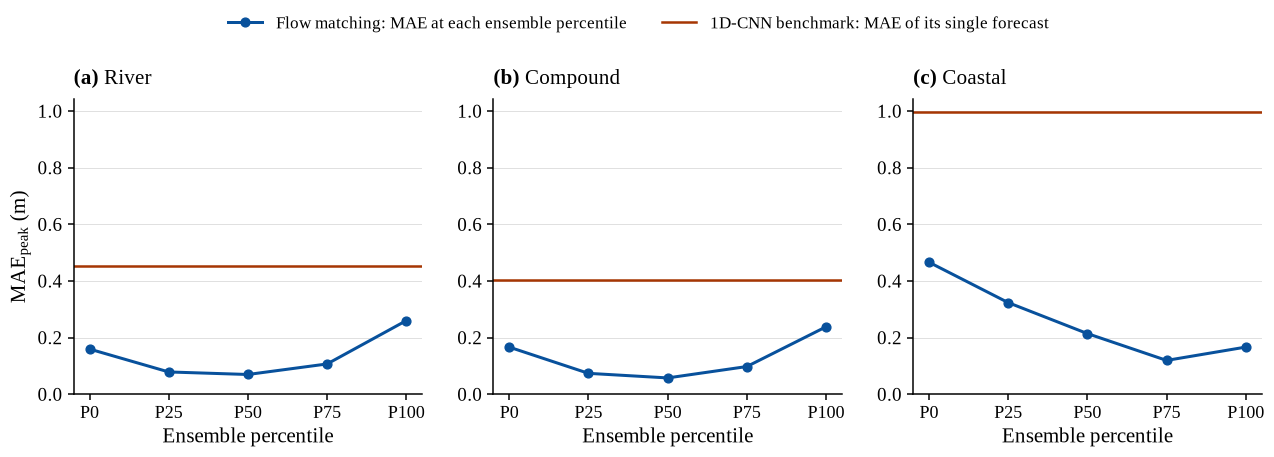

Peak depth MAE (m) over the houses wet in the reference; first 4 h dropped
              n 1D-CNN     P0    P25    P50    P75   P100
River     9,636  0.455  0.160  0.079  0.070  0.107  0.260
Compound  9,436  0.403  0.167  0.074  0.058  0.098  0.239
Coastal   8,141  0.995  0.467  0.324  0.215  0.120  0.167


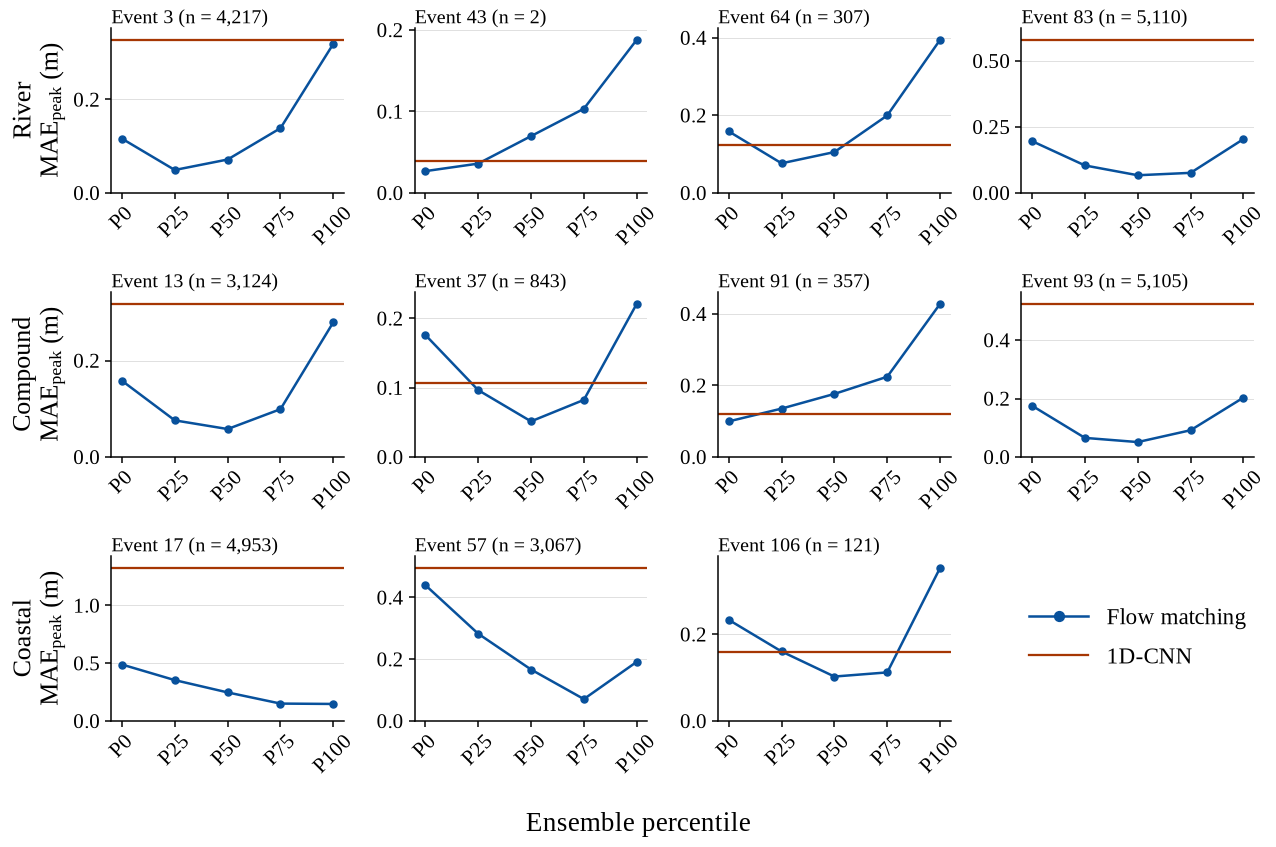

Peak depth MAE (m) per event over the houses wet in the reference; first 4 h dropped
                   n 1D-CNN    P0   P25   P50   P75  P100
Driver   Event                                           
River    3     4,217  0.328 0.116 0.049 0.071 0.139 0.319
         43        2  0.040 0.027 0.036 0.070 0.103 0.188
         64      307  0.124 0.159 0.076 0.105 0.200 0.394
         83    5,110  0.580 0.196 0.104 0.067 0.076 0.204
Compound 13    3,124  0.318 0.158 0.076 0.058 0.099 0.280
         37      843  0.107 0.176 0.096 0.051 0.082 0.221
         54        7  0.076 0.089 0.038 0.046 0.083 0.216
         91      357  0.120 0.099 0.135 0.176 0.224 0.428
         93    5,105  0.524 0.175 0.065 0.051 0.091 0.203
Coastal  17    4,953  1.325 0.489 0.354 0.247 0.150 0.147
         57    3,067  0.496 0.440 0.283 0.167 0.071 0.191
         106     121  0.159 0.233 0.160 0.102 0.112 0.353

Peak depth MAE over all 12 events (mean ± std of the per-event MAEs)
         Mean ± std (m)
Forecast 

In [30]:
# Peak depth MAE by ensemble percentile
#
# As the peak depth MAE table, over the houses wet in the reference (hits and
# misses: the same houses for every forecast), with flow matching scored at each
# percentile of its ensemble (fm_percentile_scores, from the flood arrival cell)
# and the 1D-CNN as a flat benchmark line. Absolute errors are pooled over each
# driver's house-event pairs.
def wet_peak_mae(scores):
    """Peak depth MAE per driver over the houses wet in the reference."""
    wet = scores[scores["exposure_outcome"].isin(["hit", "miss"])]
    return wet["peak_depth_error"].abs().groupby(wet["scenario_id"].map(regime_of)).agg(["mean", "size"])

fm_mae = {label.replace("FM ", ""): wet_peak_mae(fm_percentile_scores[column])
          for column, label in ARRIVAL_SERIES.items()}
cnn_mae = wet_peak_mae(model_scores["cnn1d"])

fig, axes = plt.subplots(1, len(regimes), figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.36), sharey=True)
x = np.arange(len(fm_mae))
for i, (ax, regime) in enumerate(zip(axes, regimes)):
    ax.plot(x, [fm_mae[label].loc[regime, "mean"] for label in fm_mae], "o-", color=fm_colour,
            lw=1.2 * _SCALE, ms=3.5 * _SCALE, label="Flow matching: MAE at each ensemble percentile")
    ax.axhline(cnn_mae.loc[regime, "mean"], color=cnn_colour, lw=1.0 * _SCALE,
               label="1D-CNN benchmark: MAE of its single forecast")
    ax.set_xticks(x)
    ax.set_xticklabels(list(fm_mae), fontsize=BASE_FONT_PT - 1.5)
    ax.set_xlabel("Ensemble percentile")
    ax.tick_params(labelleft=True)
    if i == 0:
        ax.set_ylabel("$\\mathrm{MAE}_{\\mathrm{peak}}$ (m)")
    panel_title(ax, chr(97 + i), SHORT_NAMES[regime], pad=6)
    style_axes(ax)
axes[0].set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False,
           fontsize=BASE_FONT_PT - 2)
fig.tight_layout(w_pad=1.5, rect=(0, 0, 1, 0.9))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_depth_mae_by_percentile.{ext}"), dpi=600)
plt.show()

table = pd.DataFrame({SHORT_NAMES[regime]: {"n": f"{int(cnn_mae.loc[regime, 'size']):,}",
                                            "1D-CNN": f"{cnn_mae.loc[regime, 'mean']:.3f}",
                                            **{label: f"{mae.loc[regime, 'mean']:.3f}" for label, mae in fm_mae.items()}}
                      for regime in regimes}).T
print(f"Peak depth MAE (m) over the houses wet in the reference; first {SKIP_FIRST_STEPS} h dropped")
print(table.to_string())

# The same per event, in the layout of the detection-by-event figure but with
# rows River, Compound, Coastal (the legend in the empty slot at the end of the
# shorter Coastal row; the same events left out); n = houses wet in the reference in that event. Each panel has its own
# depth scale from 0: event MAEs range from a few cm to over 1 m (1D-CNN, event 17).
def wet_peak_mae_by_event(scores):
    """Peak depth MAE per event over the houses wet in the reference."""
    wet = scores[scores["exposure_outcome"].isin(["hit", "miss"])]
    return wet["peak_depth_error"].abs().groupby(wet["scenario_id"]).agg(["mean", "size"])

fm_event_mae = {label: wet_peak_mae_by_event(fm_percentile_scores[column])
                for label, column in zip(fm_mae, ARRIVAL_SERIES)}
cnn_event_mae = wet_peak_mae_by_event(model_scores["cnn1d"])

mae_plot_regimes = ["River-dominated", "Compound", "Coastal-dominated"]
fig, grid = plt.subplots(len(mae_plot_regimes), n_columns, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66),
                         sharex=True)
x = np.arange(len(fm_event_mae))
for row, regime in enumerate(mae_plot_regimes):
    for col in range(n_columns):
        ax = grid[row, col]
        if col >= len(plot_events[regime]):
            ax.set_axis_off()
            continue
        event = plot_events[regime][col]
        ax.plot(x, [mae.loc[event, "mean"] for mae in fm_event_mae.values()], "o-", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching")
        ax.axhline(cnn_event_mae.loc[event, "mean"], color=cnn_colour, lw=0.9 * _SCALE,
                   label="1D-CNN")
        ax.set_title(f"Event {event} (n = {int(cnn_event_mae.loc[event, 'size']):,})",
                     fontsize=BASE_FONT_PT, loc="left", pad=3)
        ax.set_xticks(x)
        ax.set_xticklabels(list(fm_event_mae), fontsize=BASE_FONT_PT + 0.5, rotation=45)
        ax.tick_params(axis="y", labelsize=BASE_FONT_PT + 0.5)
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.set_ylim(0, max(cnn_event_mae.loc[event, "mean"],
                           *(mae.loc[event, "mean"] for mae in fm_event_mae.values())) * 1.08)
        if col == 0:
            ax.set_ylabel(f"{SHORT_NAMES[regime]}\n$\\mathrm{{MAE}}_{{\\mathrm{{peak}}}}$ (m)", fontsize=BASE_FONT_PT + 4)
        style_axes(ax)
fig.supxlabel("Ensemble percentile", fontsize=BASE_FONT_PT + 5)
fig.tight_layout(h_pad=1.2, w_pad=1.0)
handles, legend_labels = grid[0, 0].get_legend_handles_labels()
slot = next(ax for ax in grid.flat if not ax.axison).get_position()
fig.legend(handles, legend_labels, loc="center", frameon=False, fontsize=BASE_FONT_PT + 2,
           handlelength=2.6, markerscale=1.4, labelspacing=0.8,
           bbox_to_anchor=((slot.x0 + slot.x1) / 2, (slot.y0 + slot.y1) / 2))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_depth_mae_by_event.{ext}"), dpi=600)
plt.show()

event_mae_table = pd.DataFrame({"n": cnn_event_mae["size"], "1D-CNN": cnn_event_mae["mean"],
                                **{label: mae["mean"] for label, mae in fm_event_mae.items()}}).reindex(events)
event_mae_table.index = pd.MultiIndex.from_tuples(
    [(SHORT_NAMES[regime_of[event]], event) for event in events], names=["Driver", "Event"])
print(f"Peak depth MAE (m) per event over the houses wet in the reference; first {SKIP_FIRST_STEPS} h dropped")
print(event_mae_table.to_string(formatters={"n": "{:,.0f}".format,
                                            **{c: "{:.3f}".format for c in event_mae_table.columns if c != "n"}}))

# Overall: mean +- standard deviation of the per-event MAEs above, over all
# events (each event weighted equally, whatever its number of wet houses).
event_maes = event_mae_table.drop(columns="n")
overall_mae = pd.DataFrame({"Mean \u00b1 std (m)": [f"{event_maes[c].mean():.3f} \u00b1 {event_maes[c].std():.3f}"
                                                   for c in event_maes.columns]},
                           index=pd.Index(event_maes.columns, name="Forecast"))
print(f"\nPeak depth MAE over all {len(event_maes)} events (mean \u00b1 std of the per-event MAEs)")
print(overall_mae.to_string())


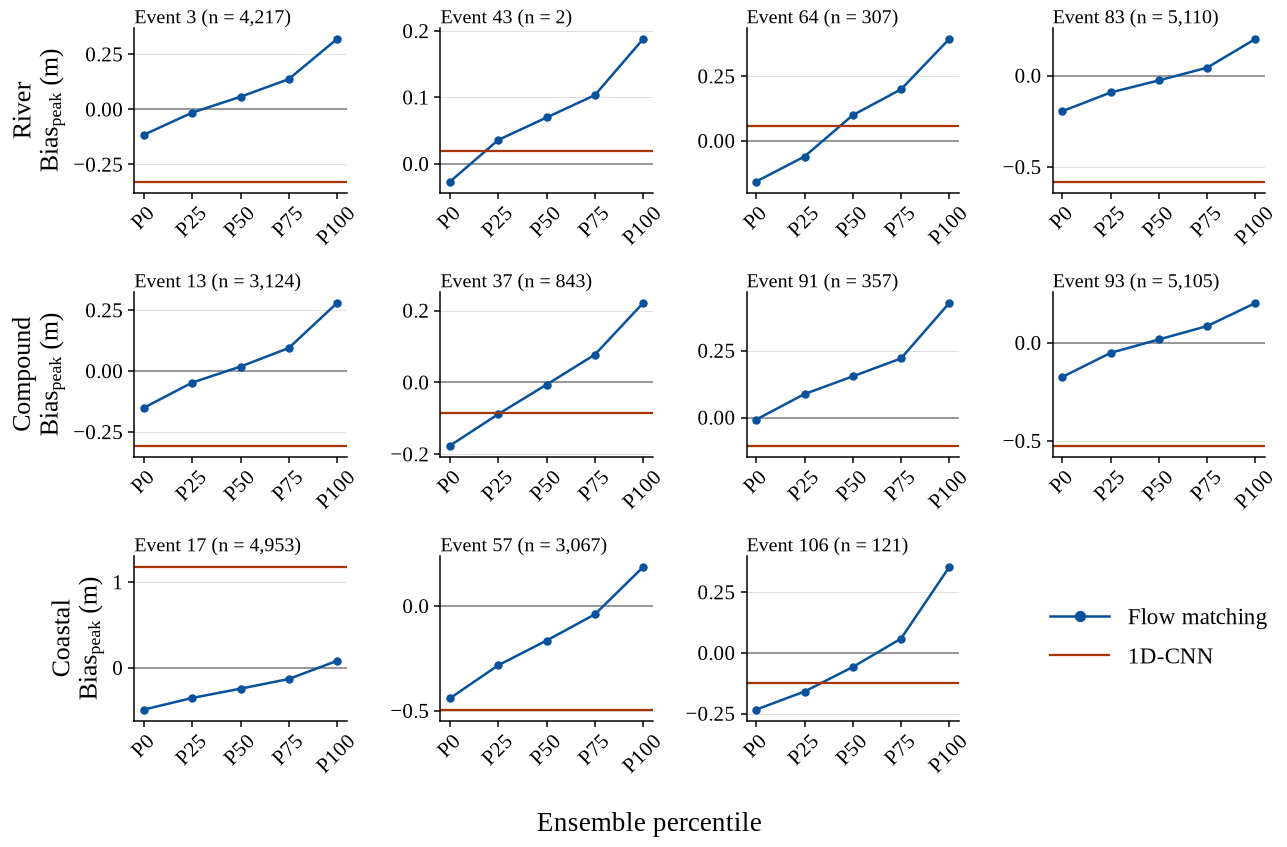

Peak depth bias (m) per event over the houses wet in the reference; first 4 h dropped
                   n 1D-CNN     P0    P25    P50    P75   P100
Driver   Event                                                
River    3     4,217 -0.327 -0.115 -0.015 +0.057 +0.137 +0.319
         43        2 +0.019 -0.027 +0.036 +0.070 +0.103 +0.188
         64      307 +0.055 -0.158 -0.061 +0.099 +0.199 +0.394
         83    5,110 -0.580 -0.195 -0.093 -0.027 +0.043 +0.200
Compound 13    3,124 -0.306 -0.151 -0.047 +0.018 +0.094 +0.279
         37      843 -0.086 -0.176 -0.088 -0.006 +0.077 +0.221
         54        7 -0.062 -0.089 -0.038 +0.021 +0.069 +0.216
         91      357 -0.105 -0.008 +0.088 +0.154 +0.221 +0.428
         93    5,105 -0.524 -0.174 -0.052 +0.017 +0.085 +0.202
Coastal  17    4,953 +1.175 -0.488 -0.353 -0.245 -0.132 +0.080
         57    3,067 -0.494 -0.440 -0.282 -0.165 -0.040 +0.186
         106     121 -0.123 -0.233 -0.159 -0.058 +0.059 +0.353

Peak depth bias over all 12 eve

In [31]:
# Peak depth bias by ensemble percentile, per event
#
# As the peak depth MAE by event (same houses: wet in the reference; same layout
# and events), but the signed mean of model peak depth - simulation peak depth:
# negative = the forecast is too shallow. Each panel has its own scale, always
# including zero (grey line).
def wet_peak_bias_by_event(scores):
    """Peak depth bias per event over the houses wet in the reference."""
    wet = scores[scores["exposure_outcome"].isin(["hit", "miss"])]
    return wet["peak_depth_error"].groupby(wet["scenario_id"]).agg(["mean", "size"])

fm_event_bias = {label: wet_peak_bias_by_event(fm_percentile_scores[column])
                 for label, column in zip(fm_mae, ARRIVAL_SERIES)}
cnn_event_bias = wet_peak_bias_by_event(model_scores["cnn1d"])

fig, grid = plt.subplots(len(mae_plot_regimes), n_columns, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66),
                         sharex=True)
x = np.arange(len(fm_event_bias))
for row, regime in enumerate(mae_plot_regimes):
    for col in range(n_columns):
        ax = grid[row, col]
        if col >= len(plot_events[regime]):
            ax.set_axis_off()
            continue
        event = plot_events[regime][col]
        ax.axhline(0, color="0.6", lw=0.8 * _SCALE, zorder=1)
        ax.plot(x, [bias.loc[event, "mean"] for bias in fm_event_bias.values()], "o-", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching")
        ax.axhline(cnn_event_bias.loc[event, "mean"], color=cnn_colour, lw=0.9 * _SCALE,
                   label="1D-CNN")
        ax.set_title(f"Event {event} (n = {int(cnn_event_bias.loc[event, 'size']):,})",
                     fontsize=BASE_FONT_PT, loc="left", pad=3)
        ax.set_xticks(x)
        ax.set_xticklabels(list(fm_event_bias), fontsize=BASE_FONT_PT + 0.5, rotation=45)
        ax.tick_params(axis="y", labelsize=BASE_FONT_PT + 0.5)
        ax.tick_params(labelbottom=True, labelleft=True)
        values = [0, cnn_event_bias.loc[event, "mean"], *(bias.loc[event, "mean"] for bias in fm_event_bias.values())]
        pad = 0.08 * (max(values) - min(values))
        ax.set_ylim(min(values) - pad, max(values) + pad)
        if col == 0:
            ax.set_ylabel(f"{SHORT_NAMES[regime]}\n$\\mathrm{{Bias}}_{{\\mathrm{{peak}}}}$ (m)", fontsize=BASE_FONT_PT + 4)
        style_axes(ax)
fig.supxlabel("Ensemble percentile", fontsize=BASE_FONT_PT + 5)
fig.tight_layout(h_pad=1.2, w_pad=1.0)
handles, legend_labels = grid[0, 0].get_legend_handles_labels()
slot = next(ax for ax in grid.flat if not ax.axison).get_position()
fig.legend(handles, legend_labels, loc="center", frameon=False, fontsize=BASE_FONT_PT + 2,
           handlelength=2.6, markerscale=1.4, labelspacing=0.8,
           bbox_to_anchor=((slot.x0 + slot.x1) / 2, (slot.y0 + slot.y1) / 2))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_depth_bias_by_event.{ext}"), dpi=600)
plt.show()

event_bias_table = pd.DataFrame({"n": cnn_event_bias["size"], "1D-CNN": cnn_event_bias["mean"],
                                 **{label: bias["mean"] for label, bias in fm_event_bias.items()}}).reindex(events)
event_bias_table.index = pd.MultiIndex.from_tuples(
    [(SHORT_NAMES[regime_of[event]], event) for event in events], names=["Driver", "Event"])
print(f"Peak depth bias (m) per event over the houses wet in the reference; first {SKIP_FIRST_STEPS} h dropped")
print(event_bias_table.to_string(formatters={"n": "{:,.0f}".format,
                                             **{c: "{:+.3f}".format for c in event_bias_table.columns if c != "n"}}))

# Overall: mean +- standard deviation of the per-event biases, each event weighted equally.
event_biases = event_bias_table.drop(columns="n")
overall_bias = pd.DataFrame({"Mean \u00b1 std (m)": [f"{event_biases[c].mean():+.3f} \u00b1 {event_biases[c].std():.3f}"
                                                    for c in event_biases.columns]},
                            index=pd.Index(event_biases.columns, name="Forecast"))
print(f"\nPeak depth bias over all {len(event_biases)} events (mean \u00b1 std of the per-event biases)")
print(overall_bias.to_string())


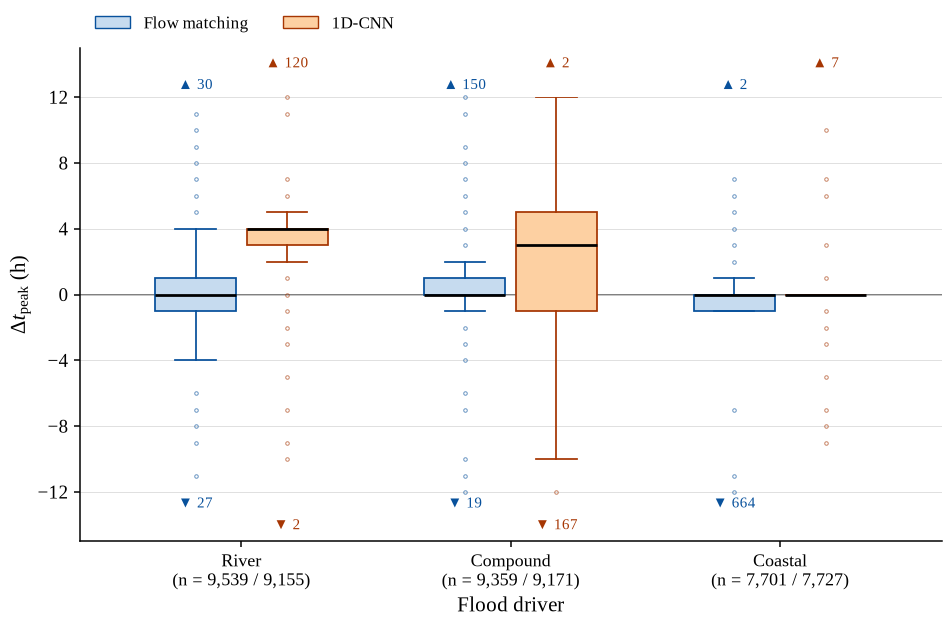

         Flow matching: n Flow matching: median [IQR] (h) Flow matching: within 1 h Flow matching: beyond ±12 h 1D-CNN: n 1D-CNN: median [IQR] (h) 1D-CNN: within 1 h 1D-CNN: beyond ±12 h
River               9,539                     +0 [-1, +1]                       88%                          57     9,155              +4 [+3, +4]                16%                  122
Compound            9,359                     +0 [+0, +1]                       86%                         169     9,171              +3 [-1, +5]                32%                  169
Coastal             7,701                     +0 [-1, +0]                       82%                         666     7,727              +0 [+0, +0]                98%                    7


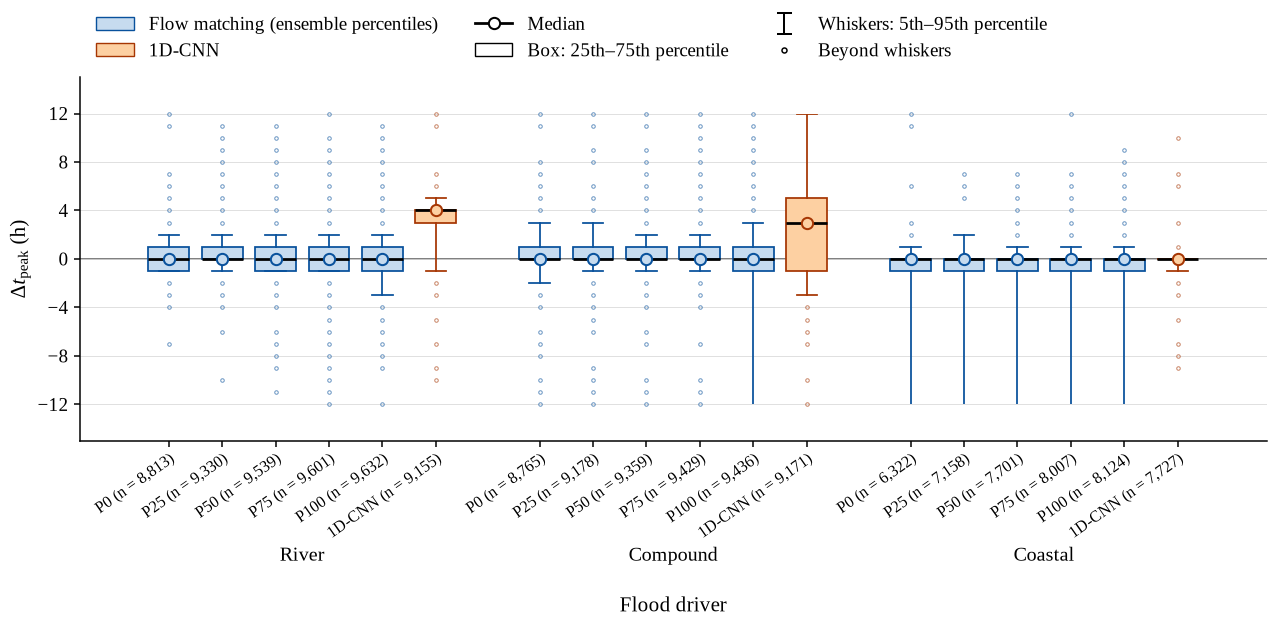

Peak time difference over each forecast's own hits; first 4 h dropped
                       n median [IQR] (h) within 1 h beyond ±12 h
Driver   Forecast                                                
River    FM P0     8,813      +0 [-1, +1]        91%           23
Compound FM P0     8,765      +0 [+0, +1]        81%          170
Coastal  FM P0     6,322      +0 [-1, +0]        78%          767
River    FM P25    9,330      +0 [+0, +1]        86%           54
Compound FM P25    9,178      +0 [+0, +1]        83%          163
Coastal  FM P25    7,158      +0 [-1, +0]        77%          713
River    FM P50    9,539      +0 [-1, +1]        88%           57
Compound FM P50    9,359      +0 [+0, +1]        86%          169
Coastal  FM P50    7,701      +0 [-1, +0]        82%          666
River    FM P75    9,601      +0 [-1, +1]        86%           54
Compound FM P75    9,429      +0 [+0, +1]        86%          167
Coastal  FM P75    8,007      +0 [-1, +0]        84%          695
River 

In [32]:
# Box plot of the peak time difference, Delta t_peak = hour of the model's peak
# depth minus the hour of the simulation's (the reference), per house, pooled by
# driver, both models side by side. A peak time exists only where the model
# floods the house, so each model is timed on the houses it identified correctly
# (its hits) and n differs between the two, as for the flood arrival time.
# Drawn with paired_boxes (the flood arrival cell), cropped to +-PEAK_LIMIT_H.
PEAK_LIMIT_H = 12
fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN * 0.75, FIG_WIDTH_IN * 0.5))
paired_boxes(ax, "peak_time_error_h", PEAK_LIMIT_H, 4, houses=("hit",))
ax.set_ylabel("$\\Delta t_{\\mathrm{peak}}$ (h)")
model_legend(ax, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_time_difference_by_driver.{ext}"), dpi=600)
plt.show()

# Per driver and model: the houses timed, the median [IQR] difference, the share
# within one hour and the houses beyond the plotted window.
summary = {}
for model in RUN_CONFIGS:
    hits = model_scores[model][model_scores[model]["exposure_outcome"] == "hit"].dropna(subset=["peak_time_error_h"])
    for regime, values in hits.groupby(hits["scenario_id"].map(regime_of))["peak_time_error_h"]:
        row = summary.setdefault(SHORT_NAMES[regime], {})
        label = MODEL_LABELS[model]
        row[f"{label}: n"] = f"{len(values):,}"
        row[f"{label}: median [IQR] (h)"] = (
            f"{values.median():+.0f} [{values.quantile(.25):+.0f}, {values.quantile(.75):+.0f}]")
        row[f"{label}: within 1 h"] = f"{(values.abs() <= 1).mean():.0%}"
        row[f"{label}: beyond \u00b1{PEAK_LIMIT_H} h"] = int((values.abs() > PEAK_LIMIT_H).sum())
print(pd.DataFrame(summary).T.reindex([SHORT_NAMES[r] for r in regimes]).to_string())

# The same with flow matching at each percentile of its ensemble, in the layout
# of the percentile flood arrival figure (percentile_boxes, flood arrival cell).
summary = percentile_boxes("peak_time_error_h", PEAK_LIMIT_H, 4, "$\\Delta t_{\\mathrm{peak}}$ (h)",
                           "fig_peak_time_difference_by_driver_percentiles")
print(f"Peak time difference over each forecast's own hits; first {SKIP_FIRST_STEPS} h dropped")
print(pd.DataFrame(summary).T.rename_axis(["Driver", "Forecast"]).to_string())
